# Assignment 5 : REGRESSION TECHNIQUES

In [1]:
student_name='\u0906\u092F\u0941\u0937\u0020\u0915\u0941\u092E\u093E\u0930'
print("STUDENT NAME: ",student_name)

STUDENT NAME:  आयुष कुमार


In [2]:
submited_to='\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947'
print("SUBMITED TO: ",submited_to)

SUBMITED TO:  वैशाली इंगळे


# Importing Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [4]:
RANDOM_STATE=91

# Data Pre-Processing

In [5]:
df = pd.read_csv("housing.csv")
df.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
## Printing number of samples and features in our dataset.
print("Number of samples: ",df.shape[0])
print("Number of features: ",df.shape[1])

Number of samples:  20640
Number of features:  10


In [7]:
## Printing feature name alongwith its total values present and its data type
for col in df.columns:
    print(f'feature Name = "{col}",' , f'Total Values Present = {df[col].count()},',  f'Data Type = {df[col].dtype}')

feature Name = "longitude", Total Values Present = 20640, Data Type = float64
feature Name = "latitude", Total Values Present = 20640, Data Type = float64
feature Name = "housing_median_age", Total Values Present = 20640, Data Type = float64
feature Name = "total_rooms", Total Values Present = 20640, Data Type = float64
feature Name = "total_bedrooms", Total Values Present = 20433, Data Type = float64
feature Name = "population", Total Values Present = 20640, Data Type = float64
feature Name = "households", Total Values Present = 20640, Data Type = float64
feature Name = "median_income", Total Values Present = 20640, Data Type = float64
feature Name = "median_house_value", Total Values Present = 20640, Data Type = float64
feature Name = "ocean_proximity", Total Values Present = 20640, Data Type = object


In [8]:
## no need of longitute and latitude.
df = df.drop(columns=["longitude", "latitude"])
df.head()

,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [9]:
for col in df.columns:
    print(f"Column Name      : {col}")
    print(f"Missing Values   : {df[col].isnull().sum()}")
    print("-" * 35)

Column Name      : housing_median_age
Missing Values   : 0
-----------------------------------
Column Name      : total_rooms
Missing Values   : 0
-----------------------------------
Column Name      : total_bedrooms
Missing Values   : 207
-----------------------------------
Column Name      : population
Missing Values   : 0
-----------------------------------
Column Name      : households
Missing Values   : 0
-----------------------------------
Column Name      : median_income
Missing Values   : 0
-----------------------------------
Column Name      : median_house_value
Missing Values   : 0
-----------------------------------
Column Name      : ocean_proximity
Missing Values   : 0
-----------------------------------


# Correlation Matrix

In [10]:
output_feature = 'median_house_value'

correlation_matrix = df.corr(numeric_only=True)[[output_feature]].sort_values(by=output_feature, ascending=False)

top_feature = correlation_matrix.index[1]
secnd_top_feature = correlation_matrix.index[2]

correlation_matrix

,median_house_value
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650


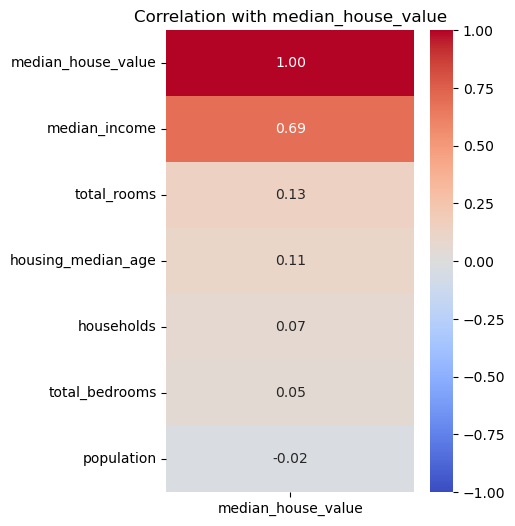

In [11]:
plt.figure(figsize=(4, 6))


sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title(f'Correlation with median_house_value')
plt.show()

#### EVALUATION OF MODEL

In [12]:
def mean_squared_error(y_actual, y_pred):
    n = len(y_actual)
    error = 0

    for i in range(n):
        error += (y_actual.iloc[i] - y_pred[i]) ** 2

    return round(error / n, 2)


def mean_absolute_error(y_actual, y_pred):
    n = len(y_actual)
    error = 0

    for i in range(n):
        error += abs(y_actual.iloc[i] - y_pred[i])

    return round(error / n, 2)


def r2_score(y_actual, y_pred):
    mean_y = sum(y_actual) / len(y_actual)

    ss_total = 0
    ss_residual = 0

    for i in range(len(y_actual)):
        ss_total += (y_actual.iloc[i] - mean_y) ** 2
        ss_residual += (y_actual.iloc[i] - y_pred[i]) ** 2

    return round(1 - (ss_residual / ss_total), 2)

# train Test split

In [13]:
X = df[[top_feature]]
y = df[output_feature]

In [14]:
model = LinearRegression()

In [15]:
split_results = []

for train_percent in np.arange(0.1, 1.0, 0.1):

    X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=train_percent, random_state=RANDOM_STATE)

    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Training Error
    train_error = mean_squared_error(y_train, train_pred)

    # Testing Error
    test_error = mean_squared_error(y_test, test_pred)

    split_results.append([
        train_percent,
        train_error,
        test_error
    ])

split_df = pd.DataFrame(
    split_results,
    columns=[
        "Training %",
        "Training Error",
        "Testing Error"
    ]
)


In [16]:
split_df["Difference"] = abs(split_df["Training Error"] - split_df["Testing Error"])

best_split = split_df.sort_values("Difference").iloc[0]["Training %"]

print("Best Training Split:", best_split, "%")

Best Training Split: 0.7000000000000001 %


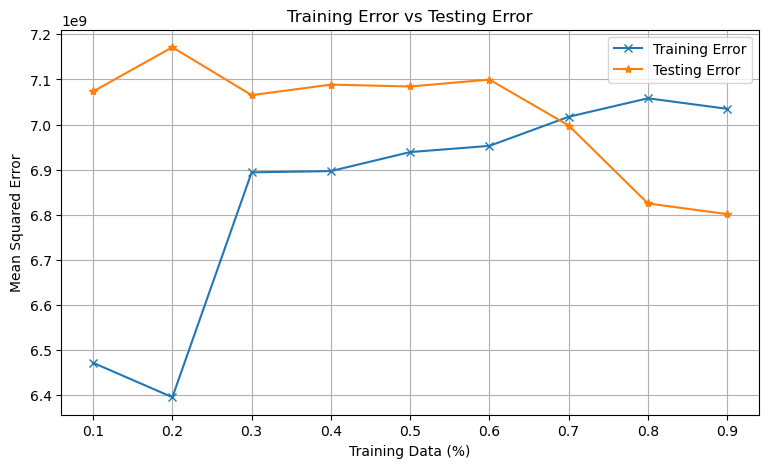

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(
    split_df["Training %"],
    split_df["Training Error"],
    marker="x",
    label="Training Error"
)

plt.plot(
    split_df["Training %"],
    split_df["Testing Error"],
    marker="*",
    label="Testing Error"
)

plt.xlabel("Training Data (%)")
plt.ylabel("Mean Squared Error")
plt.title("Training Error vs Testing Error")

plt.legend()
plt.grid()

plt.show()

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=best_split/100,random_state=RANDOM_STATE)

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [19]:
print("Coefficient: ", np.round(model.coef_, 2))

print("Intercept: ", round(float(model.intercept_), 2))

Coefficient:  [43048.73]
Intercept:  38094.09


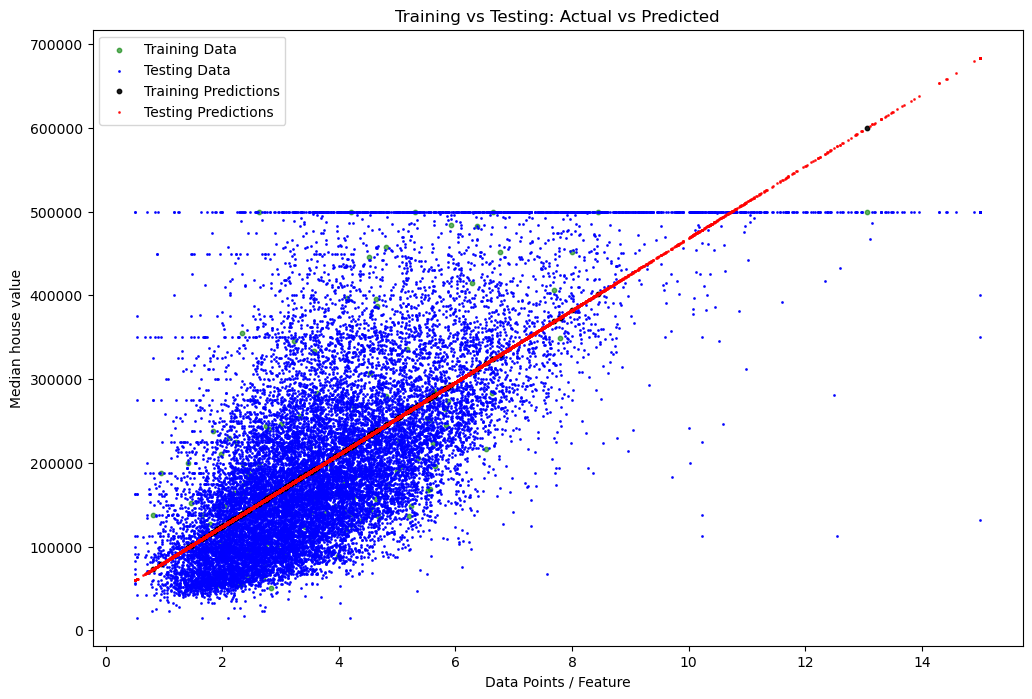

In [24]:
plt.figure(figsize=(12, 8))

# Actual training data
plt.scatter(X_train, y_train,color="green",label="Training Data",alpha=0.6,s=10)

# Actual testing data
plt.scatter(X_test, y_test,color="blue",label="Testing Data",alpha=0.9,s=1)

# Prediction for training data
plt.scatter(X_train, y_train_pred,color="black",label="Training Predictions",alpha=0.9,s=10)

# Prediction for testing data
plt.scatter(X_test, y_test_pred,color="red",label="Testing Predictions",alpha=0.8,s=1)

plt.xlabel("Data Points / Feature")
plt.ylabel("Median house value")
plt.title("Training vs Testing: Actual vs Predicted")

plt.legend()
plt.show()

In [24]:
# Training errors
Lin_train_mse = mean_squared_error(y_train, y_train_pred)
Lin_train_mae = mean_absolute_error(y_train, y_train_pred)
Lin_train_r2 = r2_score(y_train, y_train_pred)

# Testing errors
Lin_test_mse = mean_squared_error(y_test, y_test_pred)
Lin_test_mae = mean_absolute_error(y_test, y_test_pred)
Lin_test_r2 = r2_score(y_test, y_test_pred)


print("Simple Linear Regression Results")
print("---------------------------------")

print(f"Training Data : {best_split}%")
print(f"Testing Data  : {100 - best_split}%")
print()

print("Training Performance")
print("MSE            :", round(Lin_train_mse, 3))
print("MAE            :", round(Lin_train_mae, 3))
print("R2 Score       :", round(Lin_train_r2, 3))
print()

print("Testing Performance")
print("MSE            :", round(Lin_test_mse, 3))
print("MAE            :", round(Lin_test_mae, 3))
print("R2 Score       :", round(Lin_test_r2, 3))

Simple Linear Regression Results
---------------------------------
Training Data : 0.7000000000000001%
Testing Data  : 99.3%

Training Performance
MSE            : 8086246251.15
MAE            : 70575.32
R2 Score       : 0.4

Testing Performance
MSE            : 7014069634.12
MAE            : 62073.83
R2 Score       : 0.47


## POLYNOMIAL

In [25]:
X = df[[top_feature, secnd_top_feature]]
y = df[output_feature] 

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=best_split,random_state=RANDOM_STATE)

In [26]:
poly = PolynomialFeatures(degree=2)

In [27]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [28]:
model = LinearRegression()
model.fit(X_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
y_train_pred_poly = model.predict(X_train_poly)
y_test_pred_poly = model.predict(X_test_poly)

In [30]:
# Metrics
poly_train_mse = mean_squared_error(y_train, y_train_pred_poly)
poly_train_mae = mean_absolute_error(y_train, y_train_pred_poly)
poly_train_r2 = r2_score(y_train, y_train_pred_poly)

poly_test_mse = mean_squared_error(y_test, y_test_pred_poly)
poly_test_mae = mean_absolute_error(y_test, y_test_pred_poly)
poly_test_r2 = r2_score(y_test, y_test_pred_poly)

#Results
print("Polynomial Regression Results")
print("------------------------------")

print("Training:")
print("MSE:", round(poly_train_mse, 3))
print("MAE:", round(poly_train_mae, 3))
print("R2 :", round(poly_train_r2, 3))

print("\nTesting:")
print("MSE:", round(poly_test_mse, 3))
print("MAE:", round(poly_test_mae, 3))
print("R2 :", round(poly_test_r2, 3))

Polynomial Regression Results
------------------------------
Training:
MSE: 6957122614.81
MAE: 62539.57
R2 : 0.48

Testing:
MSE: 6934705331.95
MAE: 62477.57
R2 : 0.48


In [ ]:
user_input_1 = float(input(f"Enter {top_feature}: "))
user_input_2 = float(input(f"Enter {secnd_top_feature}: "))

user_data = pd.DataFrame({top_feature: [user_input_1],secnd_top_feature: [user_input_2]})

user_data_poly = poly.transform(user_data)

prediction = model.predict(user_data_poly)

print("\nPredicted Output:", round(prediction[0], 3))


C:\Users\NGC LAB\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


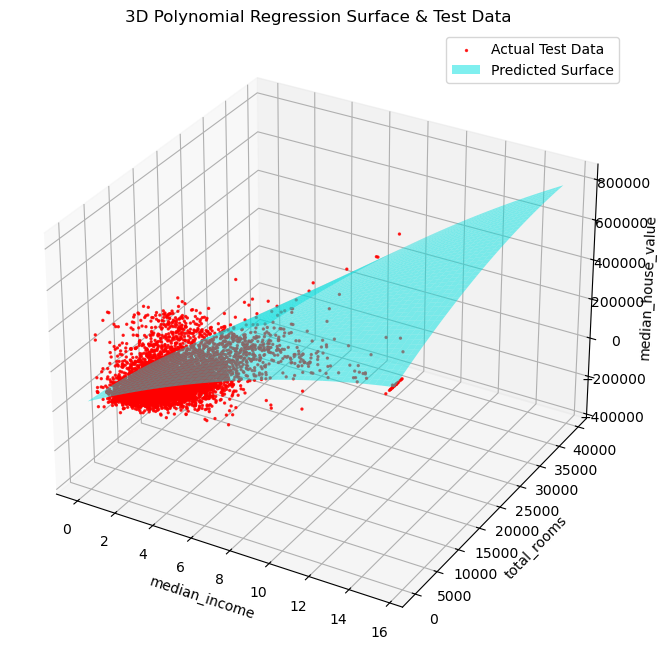

In [31]:
# Training comparison
train_comparison = pd.DataFrame(
    {
        "Actual": y_train,
        "Predicted": y_train_pred_poly,
        "Residual": y_train - y_train_pred_poly,
    }
)

# Testing comparison
test_comparison = pd.DataFrame(
    {
        "Actual": y_test,
        "Predicted": y_test_pred_poly,
        "Residual": y_test - y_test_pred_poly,
    }
)

x1_min, x1_max = X[top_feature].min() - 0.5, X[top_feature].max() + 0.5
x2_min, x2_max = (
    X[secnd_top_feature].min() - 0.5,
    X[secnd_top_feature].max() + 0.5,
)

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 50), np.linspace(x2_min, x2_max, 50)
)

# Transform grid points and predict
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
grid_points_poly = poly.transform(grid_points)
yy_pred = model.predict(grid_points_poly)
yy_pred = yy_pred.reshape(xx1.shape)

# Setup 3D figure
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection="3d")

# Scatter plot of the actual test data
ax.scatter(
    X_test[top_feature],
    X_test[secnd_top_feature],
    y_test,
    color="red",
    marker="o",
    s=2,
    label="Actual Test Data",
    alpha=0.8,
)

# Surface plot of the polynomial model
ax.plot_surface(
    xx1,
    xx2,
    yy_pred,
    color="cyan",
    alpha=0.5,
    edgecolor="none",
    label="Predicted Surface",
)

# Labels and title
ax.set_xlabel(top_feature)
ax.set_ylabel(secnd_top_feature)
ax.set_zlabel(output_feature)
ax.set_title("3D Polynomial Regression Surface & Test Data")
plt.legend()
plt.show()

In [64]:
comparison = pd.DataFrame({
    "Metric": ["MSE", "MAE", "R2 Score"],

    "Linear Regression - Training": [
        Lin_train_mse,
        Lin_train_mae,
        Lin_train_r2
    ],

    "Linear Regression - Testing": [
        Lin_test_mse,
        Lin_test_mae,
        Lin_test_r2
    ],

    "Polynomial Regression - Training": [
        poly_train_mse,
        poly_train_mae,
        poly_train_r2
    ],

    "Polynomial Regression - Testing": [
        poly_test_mse,
        poly_test_mae,
        poly_test_r2
    ]
})

comparison.round(3)

,Metric,Linear Regression - Training,Linear Regression - Testing,Polynomial Regression - Training,Polynomial Regression - Testing
0,MSE,6.893924e+09,7.065079e+09,6.934530e+09,6.913849e+09
1,MAE,6.215875e+04,6.260203e+04,6.245501e+04,6.235808e+04
2,R2 Score,4.700000e-01,4.700000e-01,4.800000e-01,4.800000e-01


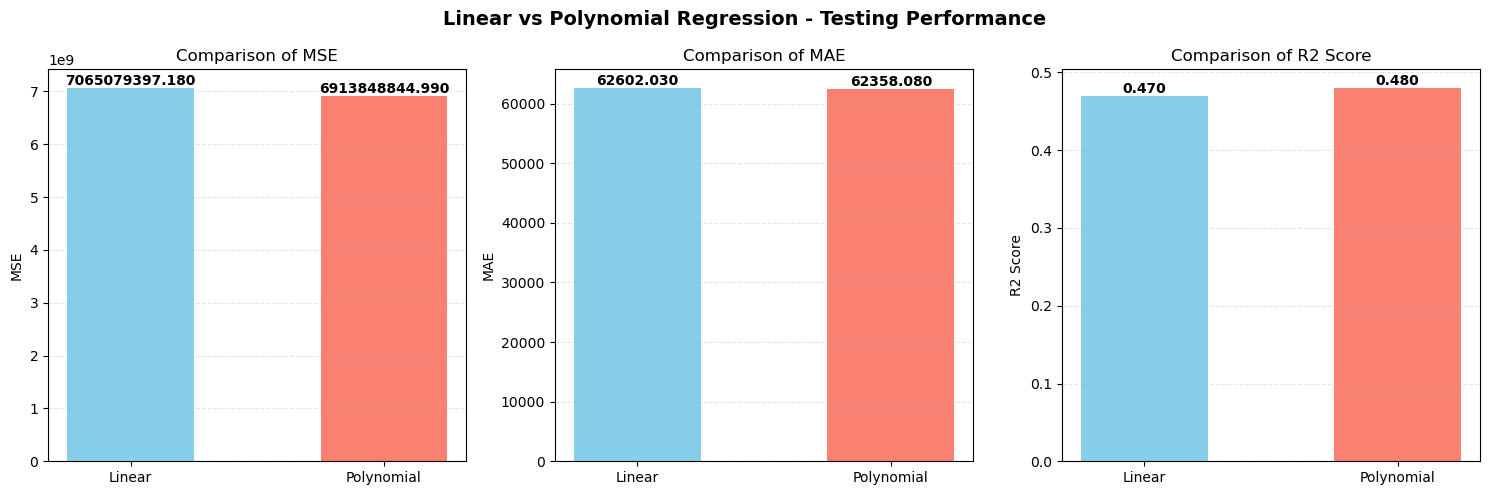

In [65]:
metrics = comparison["Metric"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = ["Linear", "Polynomial"]

for i, ax in enumerate(axes):

    values = [
        comparison["Linear Regression - Testing"].iloc[i],
        comparison["Polynomial Regression - Testing"].iloc[i]
    ]

    bars = ax.bar(models,values,color=["skyblue", "salmon"],width=0.5)

    ax.set_title(f"Comparison of {metrics.iloc[i]}")
    ax.set_ylabel(metrics.iloc[i])
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    # Add values on bars
    for bar in bars:
        value = bar.get_height()

        ax.text(bar.get_x() + bar.get_width() / 2,value,f"{value:.3f}",ha="center",va="bottom",fontweight="bold")

plt.suptitle(
    "Linear vs Polynomial Regression - Testing Performance",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()